In [2]:

from pathlib import Path
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image

# Automatically find the project root
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_DIR = CURRENT_DIR.parent
else:
    PROJECT_DIR = CURRENT_DIR

MODEL_PATH = PROJECT_DIR / "models" / "dfu_grade_model_best.keras"

IMG_SIZE = (300, 300)

CLASS_NAMES = [
    "Grade 1",
    "Grade 2",
    "Grade 3",
    "Grade 4"
]

print("Project directory:", PROJECT_DIR)
print("Model path:", MODEL_PATH)
print("Model exists:", MODEL_PATH.exists())

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Model not found: {MODEL_PATH}\n"
        "Check that dfu_grade_model_best.keras is inside "
        "the project's models folder."
    )

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully!")


Project directory: c:\Users\adhil\OneDrive\Desktop\dfu\DFU_Classification_Project
Model path: c:\Users\adhil\OneDrive\Desktop\dfu\DFU_Classification_Project\models\dfu_grade_model_best.keras
Model exists: True


Model loaded successfully!


In [3]:

# ==========================================
# CELL 2: INSPECT MODEL ARCHITECTURE
# ==========================================

print("MODEL SUMMARY")
print("=" * 60)

model.summary(expand_nested=True)

print("\nTOP-LEVEL MODEL LAYERS")
print("=" * 60)

for i, layer in enumerate(model.layers):
    try:
        output_shape = layer.output.shape
    except Exception:
        output_shape = "Unavailable"

    print(
        f"Index: {i} | "
        f"Name: {layer.name} | "
        f"Type: {type(layer).__name__} | "
        f"Output: {output_shape}"
    )

print("\nNESTED MODELS")
print("=" * 60)

for layer in model.layers:
    if isinstance(layer, tf.keras.Model):
        print(f"\nNested model name: {layer.name}")

        for inner_layer in layer.layers:
            if isinstance(inner_layer, tf.keras.layers.Conv2D):
                print(
                    f"Convolutional layer: {inner_layer.name}"
                )

print("\nArchitecture inspection completed.")


MODEL SUMMARY
Model: "DFU_EfficientNetB3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_image (InputLayer)    [(None, 300, 300, 3)]     0         
                                                                 
 random_flip (RandomFlip)    (None, 300, 300, 3)       0         
                                                                 
 random_rotation (RandomRot  (None, 300, 300, 3)       0         
 ation)                                                          
                                                                 
 efficientnetb3 (Functional  (None, 10, 10, 1536)      10783535  
 )                                                               
|¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯|
| input_1 (InputLayer)       [(None, 300, 300, 3)]     0        |
|                                                               |
| rescaling (Rescaling)      (None

Test directory: c:\Users\adhil\OneDrive\Desktop\dfu\DFU_Classification_Project\data\dfu 4 class\test
Directory exists: True


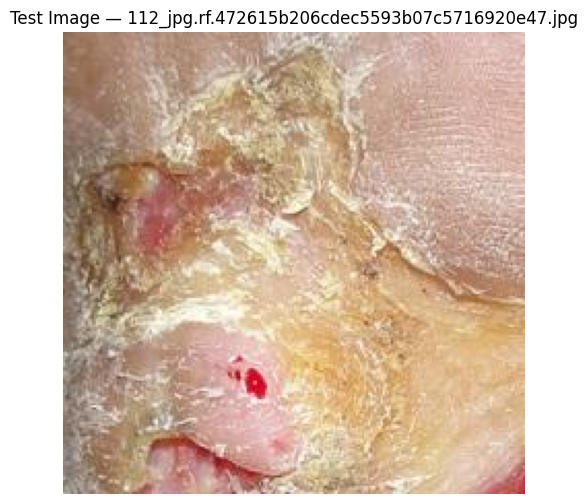

Image loaded successfully!
Actual grade: Grade 1


In [4]:

# ==========================================
# CELL 3: LOAD A TEST IMAGE
# ==========================================

TEST_DIR = PROJECT_DIR / "data" / "dfu 4 class" / "test"

print("Test directory:", TEST_DIR)
print("Directory exists:", TEST_DIR.exists())

GRADE_FOLDER = TEST_DIR / "Grade 1"

if not GRADE_FOLDER.exists():
    raise FileNotFoundError(
        f"Grade folder not found: {GRADE_FOLDER}"
    )

image_files = [
    p for p in GRADE_FOLDER.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

if not image_files:
    raise FileNotFoundError(
        f"No images found in {GRADE_FOLDER}"
    )

IMAGE_PATH = image_files[0]

original_image = Image.open(IMAGE_PATH).convert("RGB")

plt.figure(figsize=(6, 6))
plt.imshow(original_image)
plt.title(f"Test Image — {IMAGE_PATH.name}")
plt.axis("off")
plt.show()

print("Image loaded successfully!")
print("Actual grade:", GRADE_FOLDER.name)


Actual grade: Grade 1
Predicted grade: Grade 1
Model output score: 54.12%


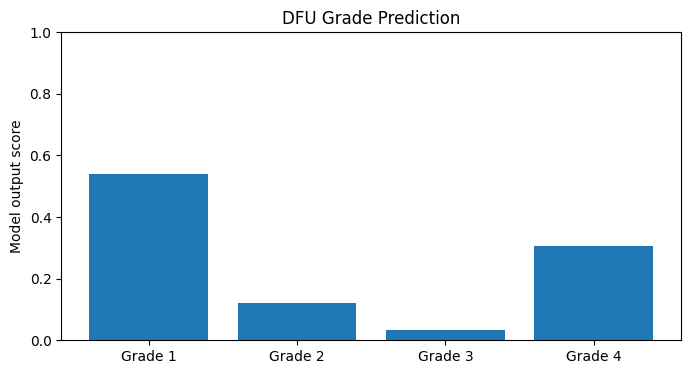

In [5]:

# ==========================================
# CELL 4: MODEL PREDICTION
# ==========================================

resized_image = original_image.resize(IMG_SIZE)

image_array = np.asarray(
    resized_image,
    dtype=np.float32
)

image_batch = np.expand_dims(image_array, axis=0)

predictions = model.predict(image_batch, verbose=0)[0]

predicted_index = int(np.argmax(predictions))
predicted_grade = CLASS_NAMES[predicted_index]
confidence = float(predictions[predicted_index])

print("Actual grade:", GRADE_FOLDER.name)
print("Predicted grade:", predicted_grade)
print(f"Model output score: {confidence:.2%}")

plt.figure(figsize=(8, 4))
plt.bar(CLASS_NAMES, predictions)
plt.ylabel("Model output score")
plt.title("DFU Grade Prediction")
plt.ylim(0, 1)
plt.show()


In [6]:

# ==========================================
# CELL 5: GENERATE GRAD-CAM
# ==========================================

# Find the nested EfficientNetB3 model.
backbone = model.get_layer("efficientnetb3")

# Get its final convolutional layer.
last_conv_layer = backbone.get_layer("top_conv")

print("Backbone:", backbone.name)
print("Grad-CAM layer:", last_conv_layer.name)

# Build a model returning convolutional features
# and the nested backbone output.
feature_model = tf.keras.Model(
    inputs=backbone.inputs,
    outputs=[
        last_conv_layer.output,
        backbone.output
    ]
)

# The outer model contains augmentation layers,
# the backbone, and the classification head.
backbone_index = model.layers.index(backbone)
head_layers = model.layers[backbone_index + 1:]

with tf.GradientTape() as tape:

    conv_outputs, backbone_features = feature_model(
        image_batch,
        training=False
    )

    predictions_for_gradcam = backbone_features

    # Pass the features through the classification head.
    for layer in head_layers:
        predictions_for_gradcam = layer(
            predictions_for_gradcam,
            training=False
        )

    class_index = tf.argmax(predictions_for_gradcam[0])

    class_score = predictions_for_gradcam[:, class_index]

# Calculate gradients of the selected class score.
gradients = tape.gradient(
    class_score,
    conv_outputs
)

if gradients is None:
    raise RuntimeError(
        "Gradients are unavailable. "
        "The classifier head or model graph needs inspection."
    )

# Average gradients across height and width.
weights = tf.reduce_mean(
    gradients,
    axis=(0, 1, 2)
)

feature_maps = conv_outputs[0]

# Combine feature maps using their gradient weights.
heatmap = tf.reduce_sum(
    feature_maps * weights,
    axis=-1
)

# Keep positive activations.
heatmap = tf.maximum(heatmap, 0)

# Normalize between 0 and 1.
maximum = tf.reduce_max(heatmap)

heatmap = tf.cond(
    maximum > 0,
    lambda: heatmap / maximum,
    lambda: heatmap
)

heatmap = heatmap.numpy()

print("Grad-CAM generated successfully!")
print("Heatmap shape:", heatmap.shape)


Backbone: efficientnetb3
Grad-CAM layer: top_conv
Grad-CAM generated successfully!
Heatmap shape: (10, 10)


C:\Users\adhil\AppData\Local\Temp\ipykernel_6048\2658332144.py:17: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colored_heatmap = cm.get_cmap("jet")(


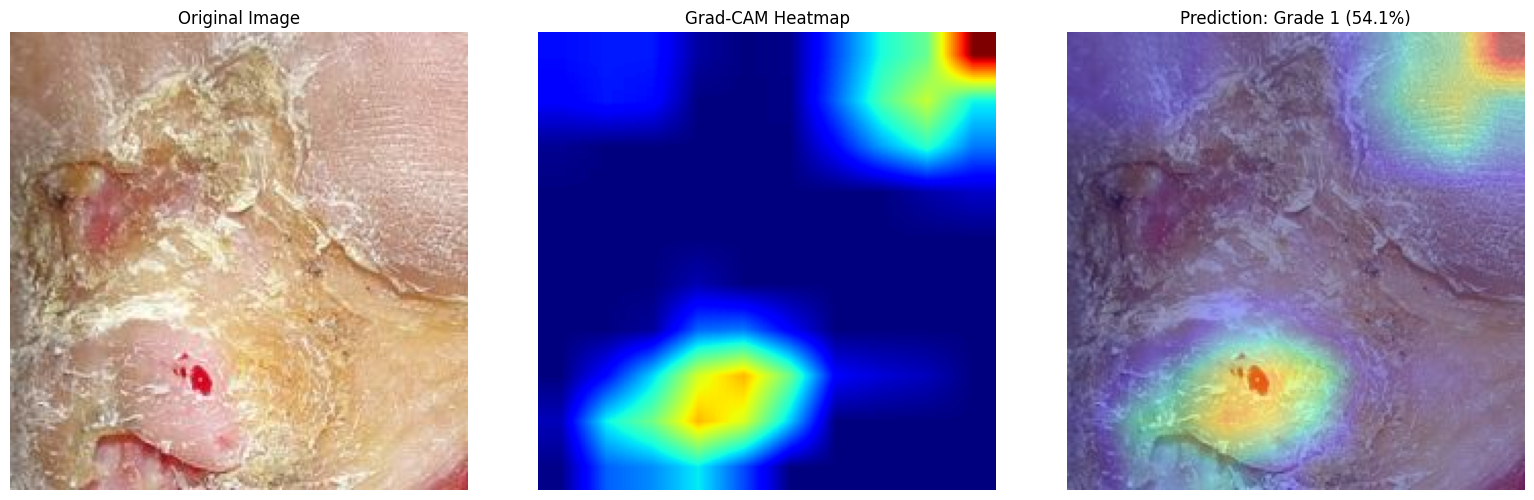

In [7]:

# ==========================================
# CELL 6: VISUALIZE GRAD-CAM
# ==========================================

import matplotlib.cm as cm

# Resize the 10 x 10 heatmap to the original image dimensions.
heatmap_resized = Image.fromarray(
    np.uint8(heatmap * 255)
).resize(original_image.size, Image.Resampling.BILINEAR)

heatmap_array = (
    np.asarray(heatmap_resized, dtype=np.float32) / 255.0
)

# Convert heatmap to colors.
colored_heatmap = cm.get_cmap("jet")(
    heatmap_array
)[..., :3]

original_array = (
    np.asarray(original_image, dtype=np.float32) / 255.0
)

# Blend the original image with the heatmap.
overlay = np.clip(
    0.6 * original_array + 0.4 * colored_heatmap,
    0,
    1
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(original_image)
axes[0].set_title("Original Image")

axes[1].imshow(heatmap_array, cmap="jet")
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(overlay)
axes[2].set_title(
    f"Prediction: {predicted_grade} ({confidence:.1%})"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


C:\Users\adhil\AppData\Local\Temp\ipykernel_6048\2658332144.py:17: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colored_heatmap = cm.get_cmap("jet")(


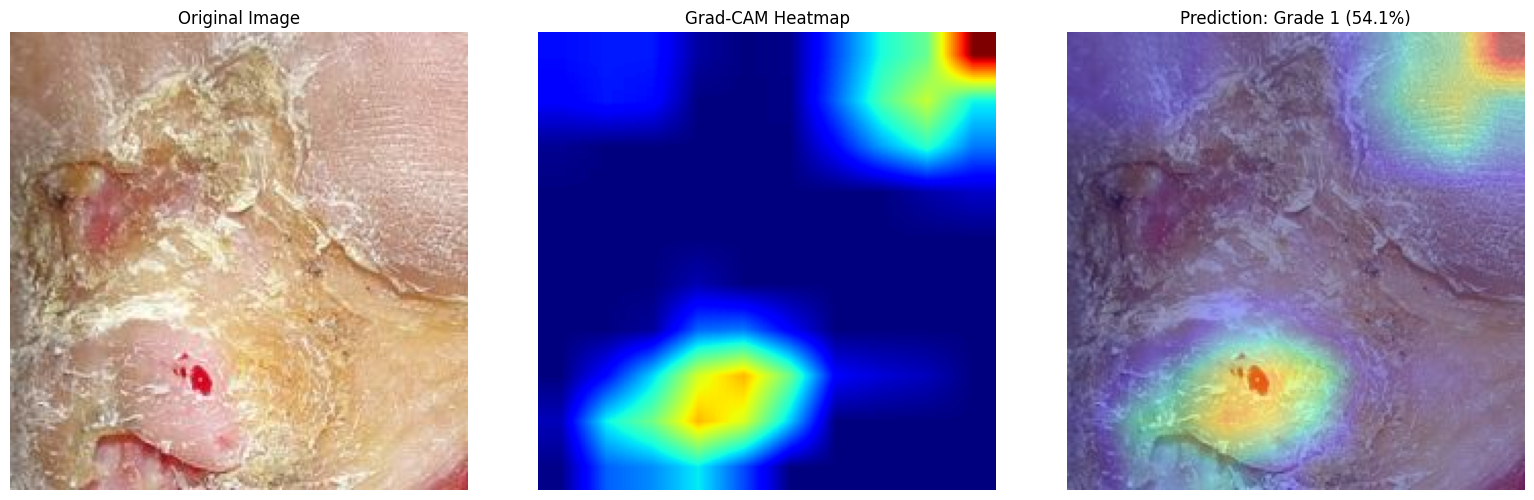

In [8]:

# ==========================================
# CELL 6: VISUALIZE GRAD-CAM
# ==========================================

import matplotlib.cm as cm

# Resize the 10 x 10 heatmap to the original image dimensions.
heatmap_resized = Image.fromarray(
    np.uint8(heatmap * 255)
).resize(original_image.size, Image.Resampling.BILINEAR)

heatmap_array = (
    np.asarray(heatmap_resized, dtype=np.float32) / 255.0
)

# Convert heatmap to colors.
colored_heatmap = cm.get_cmap("jet")(
    heatmap_array
)[..., :3]

original_array = (
    np.asarray(original_image, dtype=np.float32) / 255.0
)

# Blend the original image with the heatmap.
overlay = np.clip(
    0.6 * original_array + 0.4 * colored_heatmap,
    0,
    1
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(original_image)
axes[0].set_title("Original Image")

axes[1].imshow(heatmap_array, cmap="jet")
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(overlay)
axes[2].set_title(
    f"Prediction: {predicted_grade} ({confidence:.1%})"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [9]:

# ==========================================
# CELL 7: SAVE GRAD-CAM IMAGE
# ==========================================

OUTPUT_DIR = PROJECT_DIR / "outputs" / "gradcam"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_path = OUTPUT_DIR / f"{IMAGE_PATH.stem}_gradcam.png"

plt.imsave(output_path, overlay)

print("Grad-CAM saved to:")
print(output_path)


Grad-CAM saved to:
c:\Users\adhil\OneDrive\Desktop\dfu\DFU_Classification_Project\outputs\gradcam\112_jpg.rf.472615b206cdec5593b07c5716920e47_gradcam.png
